In [1]:
import os
import time
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import cumulative_trapezoid
import scipy.sparse as sp
import scipy.sparse.linalg as spla

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset

from numpy.polynomial.chebyshev import chebval
import json

# =========================
def set_seed(seed=2026):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    rng = np.random.default_rng(seed)

    return rng

rng = set_seed(2026)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device =", device)

device = cuda


In [ ]:
# Part1 Define reaction coefficients, integral weights, and initial values.

def make_lam_fn(beta):
    """
    lambda(x)=50*cos(beta*arccos(x)).
    x should be in [0,1].
    """
    def lam(x):
        x = np.asarray(x)
        x_clip = np.clip(x, 0.0, 1.0)
        return 50.0 * np.cos(beta * np.arccos(x_clip))
    return lam


def get_simpson_coeff(spatial):
    """
    Simpson quadrature weights on [0,1].
    If the number of intervals is not even, use trapezoidal weights.
    """
    spatial = np.asarray(spatial, dtype=float)
    N = len(spatial)
    dx = spatial[1] - spatial[0]

    if (N - 1) % 2 != 0:
        w = np.ones(N) * dx
        w[0] *= 0.5
        w[-1] *= 0.5
        return w

    w = np.ones(N)
    w[1:-1:2] = 4.0
    w[2:-1:2] = 2.0
    w *= dx / 3.0
    return w


def make_initial_profile(
    spatial,
    init_type="sin",
    amp=1.0,
    rng=None,
    n_modes=8,
    decay_power=2.0,
    normalize=True,
):
    """
    Generate an initial state satisfying u(0)=u(1)=0.

    Parameters
    ----------
    spatial : array_like
        Spatial grid on [0, 1].
    init_type : str
        Type of initial condition:
        - "zero"
        - "sin"
        - "sin2"
        - "mixed"
        - "random_sine"
        - "cheb_single"
        - "cheb_random"
    amp : float
        Amplitude of the initial profile.
    rng : np.random.Generator or None
        Random number generator. If None, a default generator is used.
    n_modes : int
        Number of modes used in random expansions.
    decay_power : float
        Decay rate for high-order coefficients.
    normalize : bool
        Whether to normalize the generated profile before multiplying by amp.

    Returns
    -------
    u0 : ndarray
        Initial profile satisfying u0(0)=u0(1)=0.
    """

    x = np.asarray(spatial, dtype=float)

    if rng is None:
        rng = np.random.default_rng()

    if init_type == "zero":
        profile = np.zeros_like(x)

    elif init_type == "sin":
        profile = np.sin(np.pi * x)

    elif init_type == "sin2":
        profile = np.sin(2.0 * np.pi * x)

    elif init_type == "mixed":
        profile = (
            0.8 * np.sin(np.pi * x)
            + 0.2 * np.sin(2.0 * np.pi * x)
        )

    elif init_type == "random_sine":
        profile = np.zeros_like(x)

        for j in range(1, n_modes + 1):
            coeff = rng.uniform(-1.0, 1.0) / (j ** decay_power)
            profile += coeff * np.sin(j * np.pi * x)

    elif init_type == "cheb_single":
        beta0 = rng.uniform(1.0, 10.0)
        x_clip = np.clip(x, 0.0, 1.0)

        profile = np.cos(beta0 * np.arccos(x_clip))

        # Enforce u0(0)=u0(1)=0.
        profile = x * (1.0 - x) * profile

    elif init_type == "cheb_random":
        xi = 2.0 * x - 1.0

        coeffs = rng.uniform(-1.0, 1.0, size=n_modes + 1)

        decay = np.array([
            (j + 1) ** (-decay_power)
            for j in range(n_modes + 1)
        ])

        coeffs = coeffs * decay

        profile = chebval(xi, coeffs)

        # Enforce u0(0)=u0(1)=0.
        profile = x * (1.0 - x) * profile

    else:
        raise ValueError(f"Unknown init_type: {init_type}")

    if normalize:
        max_abs = np.max(np.abs(profile))
        if max_abs > 1e-12:
            profile = profile / max_abs

    return amp * profile

# Some Denormalization Functions and
def denormalize_U(U_norm, stats):
    return U_norm * stats["U_std"] + stats["U_mean"]


def denormalize_p(p_norm, stats):
    return p_norm * stats["p_std"] + stats["p_mean"]


def denormalize_lam(lam_norm, stats):
    return lam_norm * stats["lam_std"] + stats["lam_mean"]



In [4]:
# Part2 Define functions to solve the controller kernel k(x,y) and observer kernel g(x,y) using Goursat marching in characteristic coordinates.
def solve_k(lambda_func, spatial, return_Kxy=False, check=False):
    """
    Solve the controller kernel k(x,y) on 0 <= y <= x <= 1.

    Kernel equation:
        k_xx(x,y) - k_yy(x,y) = lambda(y) k(x,y)

    Boundary conditions:
        k(x,0) = 0
        k(x,x) = -1/2 int_0^x lambda(s) ds

    Characteristic coordinates:
        r = x + y
        s = x - y
    """

    spatial = np.asarray(spatial, dtype=float)
    N = len(spatial)
    dx = spatial[1] - spatial[0]

    if not np.allclose(np.diff(spatial), dx):
        raise ValueError("spatial must be a uniform grid.")

    Ns = N
    Nr = 2 * N - 1

    s_grid = np.linspace(0.0, 1.0, Ns)
    r_grid = np.linspace(0.0, 2.0, Nr)
    h = s_grid[1] - s_grid[0]

    ii = np.arange(Nr)[:, None]
    jj = np.arange(Ns)[None, :]
    valid = (ii >= jj) & (ii <= (Nr - 1 - jj))

    Krs = np.full((Nr, Ns), np.nan, dtype=np.float64)

    # Boundary s=0: k(x,x)
    x_int = spatial
    lam_int = np.asarray(lambda_func(x_int), dtype=np.float64)

    F = -0.5 * cumulative_trapezoid(lam_int, x_int, initial=0.0)
    Krs[:, 0] = np.interp(r_grid / 2.0, x_int, F)

    # Boundary r=s: k(x,0)=0
    for j in range(Ns):
        Krs[j, j] = 0.0

    # Goursat marching
    for i in range(Nr - 1):
        for j in range(Ns - 1):

            if not (
                valid[i, j]
                and valid[i + 1, j]
                and valid[i, j + 1]
                and valid[i + 1, j + 1]
            ):
                continue

            if (
                np.isnan(Krs[i + 1, j])
                or np.isnan(Krs[i, j + 1])
                or np.isnan(Krs[i, j])
            ):
                continue

            r_c = 0.5 * (r_grid[i] + r_grid[i + 1])
            s_c = 0.5 * (s_grid[j] + s_grid[j + 1])
            y_c = 0.5 * (r_c - s_c)

            a_c = 0.25 * float(lambda_func(y_c))
            q = (h * h * a_c) / 4.0

            SW = Krs[i, j]
            SE = Krs[i + 1, j]
            NW = Krs[i, j + 1]

            # Semi-implicit midpoint update for NE
            # NE - SE - NW + SW = h^2 a_c * (SW+SE+NW+NE)/4
            denom = 1.0 - q
            NE = (SE + NW - SW + q * (SW + SE + NW)) / denom

            Krs[i + 1, j + 1] = NE

    # Extract k(1,y)
    r_index = np.arange(N - 1, 2 * N - 1)
    s_index = np.arange(N - 1, -1, -1)
    Kxy_gain = Krs[r_index, s_index].copy()

    Kxy = None
    if return_Kxy or check:
        Kxy = np.full((N, N), np.nan, dtype=np.float64)
        for i in range(N):
            for j in range(i + 1):
                r_idx = i + j
                s_idx = i - j
                Kxy[i, j] = Krs[r_idx, s_idx]

    if check:
        diag_err = np.nanmax(np.abs(np.diag(Kxy) - F))
        left_boundary_err = np.nanmax(np.abs(Kxy[:, 0]))

        print("solve_k consistency check:")
        print(f"  max diagonal error = {diag_err:.3e}")
        print(f"  max k(x,0) error   = {left_boundary_err:.3e}")

    if return_Kxy:
        return Krs, Kxy, Kxy_gain

    return Krs, Kxy_gain


def solve_g(lambda_func, spatial, check=False):
    """
    Directly solve the observer kernel g(x,y) on 0 <= y <= x <= 1.

    Observer kernel equation:
        g_xx(x,y) - g_yy(x,y) = -lambda(x) g(x,y)

    Boundary conditions:
        g(1,y) = 0
        g(x,x) = -1/2 int_x^1 lambda(s) ds

    Observer gain:
        g1(x) = -g(x,0)

    Return:
        Gxy     : lower-triangular array, Gxy[i,j]=g(x_i,y_j)
        g1_gain : array, g1_gain[i]=g1(x_i)
    """

    spatial = np.asarray(spatial, dtype=float)
    N = len(spatial)
    dx = spatial[1] - spatial[0]

    if not np.allclose(np.diff(spatial), dx):
        raise ValueError("spatial must be a uniform grid.")

    Ns = N
    Nr = 2 * N - 1

    s_grid = np.linspace(0.0, 1.0, Ns)
    r_grid = np.linspace(0.0, 2.0, Nr)
    h = s_grid[1] - s_grid[0]

    ii = np.arange(Nr)[:, None]
    jj = np.arange(Ns)[None, :]
    valid = (ii >= jj) & (ii <= (Nr - 1 - jj))

    Grs = np.full((Nr, Ns), np.nan, dtype=np.float64)

    # Boundary s=0: g(x,x) = -1/2 int_x^1 lambda(z) dz
    x_int = spatial
    lam_int = np.asarray(lambda_func(x_int), dtype=np.float64)

    F = cumulative_trapezoid(lam_int, x_int, initial=0.0)
    F_total = F[-1]

    x_on_r = r_grid / 2.0
    F_on_r = np.interp(x_on_r, x_int, F)

    Grs[:, 0] = -0.5 * (F_total - F_on_r)

    # Boundary x=1: r+s=2
    for j in range(Ns):
        i_right = Nr - 1 - j
        Grs[i_right, j] = 0.0

    # March from right to left
    for j in range(Ns - 1):

        i_right_next = Nr - 1 - (j + 1)

        for i in range(i_right_next - 1, j, -1):

            if not (
                valid[i, j]
                and valid[i + 1, j]
                and valid[i, j + 1]
                and valid[i + 1, j + 1]
            ):
                continue

            if (
                np.isnan(Grs[i + 1, j + 1])
                or np.isnan(Grs[i + 1, j])
                or np.isnan(Grs[i, j])
            ):
                continue

            r_c = 0.5 * (r_grid[i] + r_grid[i + 1])
            s_c = 0.5 * (s_grid[j] + s_grid[j + 1])
            x_c = 0.5 * (r_c + s_c)

            a_c = -0.25 * float(lambda_func(x_c))
            q = (h * h * a_c) / 4.0

            SW = Grs[i, j]
            SE = Grs[i + 1, j]
            NE = Grs[i + 1, j + 1]

            # Solve for NW:
            # NE - SE - NW + SW = h^2 a_c * (SW+SE+NW+NE)/4
            NW_tilde = NE - SE + SW
            NW = (NW_tilde - q * (SW + SE + NE)) / (1.0 + q)

            Grs[i, j + 1] = NW

    # Convert to g(x,y)
    Gxy = np.full((N, N), np.nan, dtype=np.float64)

    for i in range(N):
        for j in range(i + 1):
            r_idx = i + j
            s_idx = i - j
            Gxy[i, j] = Grs[r_idx, s_idx]

    # Observer gain
    g1_gain = -Gxy[:, 0].copy()

    if check:
        diag_target = -0.5 * (F_total - F)
        diag_err = np.nanmax(np.abs(np.diag(Gxy) - diag_target))
        right_err = np.nanmax(np.abs(Gxy[-1, :]))

        print("solve_g consistency check:")
        print(f"  max diagonal error = {diag_err:.3e}")
        print(f"  max g(1,y) error   = {right_err:.3e}")

    return Gxy, g1_gain

In [5]:
# Part3 Build Crank--Nicolson matrices for the interior nodes, and compute the left boundary flux using second-order finite difference.
def build_interior_CN_mats(spatial, dt, lam_profile):
    """
    Interior-node Crank--Nicolson matrices for
        v_t = v_xx + lambda(x) v.
    Boundary values are handled separately.
    """
    spatial = np.asarray(spatial, dtype=float)
    dx = spatial[1] - spatial[0]
    Nx = len(spatial)
    n_int = Nx - 2

    lam_int = lam_profile[1:-1]

    main = -2.0 / dx**2 + lam_int
    off = np.ones(n_int - 1) / dx**2

    A = sp.diags(
        [off, main, off],
        offsets=[-1, 0, 1],
        shape=(n_int, n_int),
        format="csr"
    )

    I = sp.eye(n_int, format="csr")

    M_minus = I - 0.5 * dt * A
    M_plus = I + 0.5 * dt * A

    return M_minus, M_plus


def left_flux_second_order(v, dx):
    """
    u_x(0,t) ≈ (-3u(0,t)+4u(dx,t)-u(2dx,t))/(2dx).
    """
    return (-3.0 * v[0] + 4.0 * v[1] - v[2]) / (2.0 * dx)



In [6]:
# Part4 Define a function to simulate the output-feedback trajectory using the backstepping controller and observer. 
# Define a function to simulate the open-loop response of the PDE with zero control input.

def simulate_outputfeedback_trajectory(
    lam_param,
    spatial,
    nt,
    dt,
    u0_profile,
    check_kernel=False
):
    """
    Generate one trajectory by the classical output-feedback backstepping law.

    Return:
        lam_profile : [Nx]
        p_seq       : [nt], p(t)=u_x(0,t)
        U_seq       : [nt]
        u           : [nt,Nx]
        uhat        : [nt,Nx]
    """

    spatial = np.asarray(spatial, dtype=float)
    Nx = len(spatial)
    dx = spatial[1] - spatial[0]

    lambda_func = make_lam_fn(lam_param)
    lam_profile = np.asarray(lambda_func(spatial), dtype=np.float64)

    # Controller kernel boundary gain k(1,y)
    _, k_gain = solve_k(lambda_func, spatial)
    k_gain = np.asarray(k_gain, dtype=np.float64).reshape(-1)

    # Observer gain g1(x)=-g(x,0)
    Gxy, g1_gain = solve_g(lambda_func, spatial, check=check_kernel)
    g1_gain = np.asarray(g1_gain, dtype=np.float64).reshape(-1)

    # Quadrature weights
    wq = get_simpson_coeff(spatial).astype(np.float64)

    # Algebraic boundary control:
    # U = sum_j w_j k_j uhat_j, with uhat_N = U.
    denom = 1.0 - wq[-1] * k_gain[-1]
    if abs(denom) < 1e-10:
        raise RuntimeError("The feedback denominator is too close to zero.")

    cU = (wq[1:-1] * k_gain[1:-1]) / denom

    # Interior CN matrices
    M_minus, M_plus = build_interior_CN_mats(spatial, dt, lam_profile)
    n_int = Nx - 2

    eR = np.zeros(n_int)
    eR[-1] = 1.0

    plant_solver = spla.factorized(M_minus.tocsc())

    # Observer solver with implicit U^{n+1}=cU@uhat^{n+1}
    M_obs = M_minus.tolil()
    M_obs[-1, :] -= (dt / (2.0 * dx**2)) * cU
    obs_solver = spla.factorized(M_obs.tocsc())

    u = np.zeros((nt, Nx), dtype=np.float64)
    uhat = np.zeros((nt, Nx), dtype=np.float64)
    U = np.zeros(nt, dtype=np.float64)
    p = np.zeros(nt, dtype=np.float64)
    phat = np.zeros(nt, dtype=np.float64)

    # Initial conditions
    # u[0, :] = make_initial_profile(spatial, init_type=init_type, amp=amp)
    # u0_profile =  make_initial_profile(spatial, init_type="cheb_random", amp=amp, rng=rng, n_modes=8, decay_power=2.0, normalize=True)
    u0_profile = np.asarray(u0_profile, dtype=np.float64).reshape(-1)
    u[0, :] = u0_profile
    uhat[0, :] = 0.0

    u[0, 0] = 0.0
    uhat[0, 0] = 0.0

    U[0] = float(cU @ uhat[0, 1:-1])
    u[0, -1] = U[0]
    uhat[0, -1] = U[0]

    for n in range(nt - 1):
        u_int = u[n, 1:-1]
        uh_int = uhat[n, 1:-1]

        U_old = U[n]

        p[n] = left_flux_second_order(u[n, :], dx)
        phat[n] = left_flux_second_order(uhat[n, :], dx)

        innovation = p[n] - phat[n]

        # Observer update
        rhs_hat = (
            M_plus @ uh_int
            + (dt / (2.0 * dx**2)) * U_old * eR
            + dt * g1_gain[1:-1] * innovation
        )

        uh_new_int = obs_solver(rhs_hat)

        # New control
        U_new = float(cU @ uh_new_int)

        # Plant update
        rhs_u = (
            M_plus @ u_int
            + (dt / (2.0 * dx**2)) * (U_old + U_new) * eR
        )

        u_new_int = plant_solver(rhs_u)

        u[n + 1, 0] = 0.0
        u[n + 1, 1:-1] = u_new_int
        u[n + 1, -1] = U_new

        uhat[n + 1, 0] = 0.0
        uhat[n + 1, 1:-1] = uh_new_int
        uhat[n + 1, -1] = U_new

        U[n + 1] = U_new

    p[-1] = left_flux_second_order(u[-1, :], dx)
    phat[-1] = left_flux_second_order(uhat[-1, :], dx)

    return (
        lam_profile.astype(np.float32),
        p.astype(np.float32),
        U.astype(np.float32),
        u.astype(np.float32),
        uhat.astype(np.float32),
    )



def simulate_open_loop(
    lam_param,
    spatial,
    nt,
    dt,
    init_type="sin",
    amp=10.0,
):
    """
    Open-loop response of the reaction-diffusion PDE.

    PDE:
        u_t = u_xx + lambda(x) u

    Boundary conditions:
        u(0,t)=0,
        u(1,t)=0

    This corresponds to U(t)=0.
    """

    spatial = np.asarray(spatial, dtype=float)
    Nx = len(spatial)

    lambda_func = make_lam_fn(lam_param)
    lam_profile = np.asarray(lambda_func(spatial), dtype=np.float64)

    M_minus, M_plus = build_interior_CN_mats(spatial, dt, lam_profile)
    solver = spla.factorized(M_minus.tocsc())

    u = np.zeros((nt, Nx), dtype=np.float64)

    # Initial condition
    u[0, :] = make_initial_profile(spatial, init_type=init_type, amp=amp)

    # Enforce homogeneous Dirichlet boundaries
    u[0, 0] = 0.0
    u[0, -1] = 0.0

    for n in range(nt - 1):
        u_int = u[n, 1:-1]

        rhs = M_plus @ u_int

        u_new_int = solver(rhs)

        u[n + 1, 0] = 0.0
        u[n + 1, 1:-1] = u_new_int
        u[n + 1, -1] = 0.0

    time_grid = np.arange(nt) * dt

    return {
        "time": time_grid,
        "spatial": spatial,
        "lambda": lam_profile.astype(np.float32),
        "u": u.astype(np.float32),
        "U": np.zeros(nt, dtype=np.float32),
    }

In [7]:
def build_outputfeedback_dataset(
    num_lambda,
    num_ic_per_lambda,
    spatial,
    nt,
    dt,
    beta_range=(4.0, 9.0),
    seed=2026,
    save_dir=".",
    prefix="outputfeedback_dataset",
    init_type="cheb_random",
    amp=1.0,
    amp_range=(0.2, 1.0),
    n_modes=8,
    decay_power=2.0,
    check_first=False
):
    """
    Build output-feedback dataset with multiple initial conditions
    for each sampled lambda.

    The generated dataset contains:
        lam_profiles : [N_traj, Nx]
        u0_profiles  : [N_traj, Nx]
        u_x0_seqs    : [N_traj, nt]
        U_seqs       : [N_traj, nt]
        lam_params   : [N_traj]
        lambda_ids   : [N_traj]
        ic_ids       : [N_traj]
        init_amps    : [N_traj]

    where
        N_traj = num_lambda * num_ic_per_lambda.
    """

    spatial = np.asarray(spatial, dtype=float)

    rng = np.random.default_rng(seed)

    lam_params_all = rng.uniform(
        beta_range[0],
        beta_range[1],
        size=num_lambda
    )

    lam_profiles = []
    u0_list = []
    p_list = []
    U_list = []

    lam_params_valid = []
    lambda_ids_valid = []
    ic_ids_valid = []
    init_amps_valid = []

    t0 = time.time()
    traj_count = 0

    for i, beta in enumerate(lam_params_all):
        for j in range(num_ic_per_lambda):
            try:
                if amp_range is None:
                    amp_i = float(amp)
                else:
                    amp_i = float(rng.uniform(amp_range[0], amp_range[1]))

                u0_profile = make_initial_profile(
                    spatial=spatial,
                    init_type=init_type,
                    amp=amp_i,
                    rng=rng,
                    n_modes=n_modes,
                    decay_power=decay_power,
                    normalize=True,
                )

                lam_profile, p_seq, U_seq, _, _ = simulate_outputfeedback_trajectory(
                    lam_param=beta,
                    spatial=spatial,
                    nt=nt,
                    dt=dt,
                    u0_profile=u0_profile,
                    check_kernel=(check_first and traj_count == 0)
                )

                if (
                    np.any(~np.isfinite(lam_profile))
                    or np.any(~np.isfinite(u0_profile))
                    or np.any(~np.isfinite(p_seq))
                    or np.any(~np.isfinite(U_seq))
                    or np.max(np.abs(u0_profile)) > 1e8
                    or np.max(np.abs(U_seq)) > 1e8
                    or np.max(np.abs(p_seq)) > 1e8
                ):
                    print(
                        f"Skip trajectory: "
                        f"lambda_id={i}, ic_id={j}, "
                        f"beta={beta:.4f}, amp={amp_i:.4f}"
                    )
                    continue

                lam_profiles.append(lam_profile)
                u0_list.append(u0_profile)
                p_list.append(p_seq)
                U_list.append(U_seq)

                lam_params_valid.append(beta)
                lambda_ids_valid.append(i)
                ic_ids_valid.append(j)
                init_amps_valid.append(amp_i)

            except Exception as e:
                print(
                    f"Skip trajectory: "
                    f"lambda_id={i}, ic_id={j}, "
                    f"beta={beta:.4f}, error={repr(e)}"
                )
                continue

            traj_count += 1

            if traj_count % 100 == 0:
                elapsed = time.time() - t0
                total_expected = num_lambda * num_ic_per_lambda
                print(
                    f"Generated {traj_count}/{total_expected}, "
                    f"valid={len(lam_profiles)}, "
                    f"elapsed={elapsed / 60:.1f} min"
                )

    if len(lam_profiles) == 0:
        raise RuntimeError("No valid trajectories were generated.")

    lam_profiles = np.stack(lam_profiles, axis=0).astype(np.float32)
    u0_profiles = np.stack(u0_list, axis=0).astype(np.float32)
    p_seqs = np.stack(p_list, axis=0).astype(np.float32)
    U_seqs = np.stack(U_list, axis=0).astype(np.float32)

    lam_params_valid = np.array(lam_params_valid, dtype=np.float32)
    lambda_ids_valid = np.array(lambda_ids_valid, dtype=np.int32)
    ic_ids_valid = np.array(ic_ids_valid, dtype=np.int32)
    init_amps_valid = np.array(init_amps_valid, dtype=np.float32)

    timestamp = time.strftime("%Y%m%d_%H%M%S")
    os.makedirs(save_dir, exist_ok=True)

    save_path = os.path.join(
        save_dir,
        f"{prefix}_{timestamp}.npz"
    )

    np.savez(
        save_path,
        spatial=spatial.astype(np.float32),
        dt=np.array(dt, dtype=np.float32),
        nt=np.array(nt, dtype=np.int32),

        beta_range=np.array(beta_range, dtype=np.float32),
        seed=np.array(seed, dtype=np.int32),

        num_lambda=np.array(num_lambda, dtype=np.int32),
        num_ic_per_lambda=np.array(num_ic_per_lambda, dtype=np.int32),

        init_type=np.array(init_type),
        amp=np.array(amp, dtype=np.float32),
        amp_range=np.array(
            [-1.0, -1.0] if amp_range is None else amp_range,
            dtype=np.float32
        ),
        n_modes=np.array(n_modes, dtype=np.int32),
        decay_power=np.array(decay_power, dtype=np.float32),

        lam_params=lam_params_valid,
        lambda_ids=lambda_ids_valid,
        ic_ids=ic_ids_valid,
        init_amps=init_amps_valid,

        lam_profiles=lam_profiles,
        u0_profiles=u0_profiles,
        u_x0_seqs=p_seqs,
        U_seqs=U_seqs,
    )

    print("Saved dataset to:", save_path)
    print("lam_profiles:", lam_profiles.shape)
    print("u0_profiles:", u0_profiles.shape)
    print("u_x0_seqs:", p_seqs.shape)
    print("U_seqs:", U_seqs.shape)
    print("valid trajectories:", len(lam_profiles))
    print("num_lambda:", num_lambda)
    print("num_ic_per_lambda:", num_ic_per_lambda)

    return save_path, lam_profiles, u0_profiles, p_seqs, U_seqs

In [ ]:
# Part6  Generate Output Feedback Dataset.
dx = 0.01
spatial = np.linspace(0.0, 1.0, int(round(1.0 / dx)) + 1, dtype=np.float32)

dt = 0.001
nt = 2000

save_path, lam_profiles, u0_profiles, p_seqs, U_seqs = build_outputfeedback_dataset(
    num_lambda=1000,
    num_ic_per_lambda=10,
    spatial=spatial,
    nt=nt,
    dt=dt,
    beta_range=(4.0, 9.0),
    seed=2026,
    save_dir="./data",
    prefix="outputfeedback_beta1000_ic10_chebu0",
    init_type="cheb_random",
    amp=1.0,
    amp_range=(0.2, 1.0),
    n_modes=8,
    decay_power=2.0,
    check_first=True,
)

solve_g consistency check:
  max diagonal error = 7.088e-07
  max g(1,y) error   = 0.000e+00
Generated 100/10000, valid=100, elapsed=0.2 min
Generated 200/10000, valid=200, elapsed=0.3 min
Generated 300/10000, valid=300, elapsed=0.5 min
Generated 400/10000, valid=400, elapsed=0.7 min
Generated 500/10000, valid=500, elapsed=0.8 min
Generated 600/10000, valid=600, elapsed=1.0 min
Generated 700/10000, valid=700, elapsed=1.2 min
Generated 800/10000, valid=800, elapsed=1.3 min
Generated 900/10000, valid=900, elapsed=1.5 min
Generated 1000/10000, valid=1000, elapsed=1.6 min
Generated 1100/10000, valid=1100, elapsed=1.8 min
Generated 1200/10000, valid=1200, elapsed=2.0 min
Generated 1300/10000, valid=1300, elapsed=2.1 min
Generated 1400/10000, valid=1400, elapsed=2.3 min
Generated 1500/10000, valid=1500, elapsed=2.5 min
Generated 1600/10000, valid=1600, elapsed=2.6 min
Generated 1700/10000, valid=1700, elapsed=2.8 min
Generated 1800/10000, valid=1800, elapsed=3.0 min
Generated 1900/10000, val

In [16]:
# Part 7 DataLoader
class PDEControlDataset(Dataset):
    def __init__(
        self,
        lam_profiles,
        u_x0_seqs,
        U_seqs,
        u0_profiles=None,
        stats=None,
        include_u0=False,
    ):
        self.include_u0 = include_u0

        self.lam_profiles_raw = lam_profiles.astype(np.float32)
        self.u_x0_seqs_raw = u_x0_seqs.astype(np.float32)
        self.U_seqs_raw = U_seqs.astype(np.float32)

        if u0_profiles is not None:
            self.u0_profiles_raw = u0_profiles.astype(np.float32)
        else:
            self.u0_profiles_raw = None

        if self.include_u0 and self.u0_profiles_raw is None:
            raise ValueError("include_u0=True, but u0_profiles is None.")

        if stats is None:
            stats = self.compute_stats(
                self.lam_profiles_raw,
                self.u_x0_seqs_raw,
                self.U_seqs_raw,
                self.u0_profiles_raw if self.include_u0 else None,
            )

        self.stats = stats

        self.lam_profiles = (
            self.lam_profiles_raw - stats["lam_mean"]
        ) / stats["lam_std"]

        self.u_x0_seqs = (
            self.u_x0_seqs_raw - stats["p_mean"]
        ) / stats["p_std"]

        self.U_seqs = (
            self.U_seqs_raw - stats["U_mean"]
        ) / stats["U_std"]

        self.lam_profiles = torch.from_numpy(
            self.lam_profiles.astype(np.float32)
        )

        self.u_x0_seqs = torch.from_numpy(
            self.u_x0_seqs.astype(np.float32)
        )

        self.U_seqs = torch.from_numpy(
            self.U_seqs.astype(np.float32)
        )

        if self.include_u0:
            self.u0_profiles = (
                self.u0_profiles_raw - stats["u0_mean"]
            ) / stats["u0_std"]

            self.u0_profiles = torch.from_numpy(
                self.u0_profiles.astype(np.float32)
            )
        else:
            self.u0_profiles = None

    @staticmethod
    def compute_stats(
        lam_profiles,
        u_x0_seqs,
        U_seqs,
        u0_profiles=None,
    ):
        eps = 1e-8

        stats = {
            "lam_mean": np.float32(lam_profiles.mean()),
            "lam_std": np.float32(lam_profiles.std() + eps),
            "p_mean": np.float32(u_x0_seqs.mean()),
            "p_std": np.float32(u_x0_seqs.std() + eps),
            "U_mean": np.float32(U_seqs.mean()),
            "U_std": np.float32(U_seqs.std() + eps),
        }

        if u0_profiles is not None:
            stats["u0_mean"] = np.float32(u0_profiles.mean())
            stats["u0_std"] = np.float32(u0_profiles.std() + eps)

        return stats

    def __len__(self):
        return self.lam_profiles.shape[0]

    def __getitem__(self, idx):
        if self.include_u0:
            return (
                self.lam_profiles[idx],
                self.u0_profiles[idx],
                self.u_x0_seqs[idx],
                self.U_seqs[idx],
            )

        return (
            self.lam_profiles[idx],
            self.u_x0_seqs[idx],
            self.U_seqs[idx],
        )
    


def make_loaders_from_npz(
    dataset_path,
    batch_size=64,
    lambda_val_ratio=0.1,
    lambda_test_ratio=0.1,
    seed=2026,
    include_u0=False,
):
    data = np.load(dataset_path)

    spatial = data["spatial"]
    dt = float(data["dt"])

    lam_profiles = data["lam_profiles"]
    u_x0_seqs = data["u_x0_seqs"]
    U_seqs = data["U_seqs"]

    u0_profiles = data["u0_profiles"] if "u0_profiles" in data.files else None

    if "lambda_ids" not in data.files:
        raise ValueError(
            "The dataset does not contain lambda_ids. "
            "Please regenerate the dataset with lambda_ids saved."
        )

    lambda_ids = data["lambda_ids"]

    if "ic_ids" in data.files:
        ic_ids = data["ic_ids"]
    else:
        ic_ids = None

    n_total = lam_profiles.shape[0]

    rng = np.random.default_rng(seed)

    unique_lambda_ids = np.unique(lambda_ids)
    rng.shuffle(unique_lambda_ids)

    n_lambda_total = len(unique_lambda_ids)

    n_lambda_val = int(round(lambda_val_ratio * n_lambda_total))
    n_lambda_test = int(round(lambda_test_ratio * n_lambda_total))

    if n_lambda_val <= 0:
        n_lambda_val = 1

    if n_lambda_test <= 0:
        n_lambda_test = 1

    if n_lambda_val + n_lambda_test >= n_lambda_total:
        raise ValueError(
            "lambda_val_ratio + lambda_test_ratio is too large."
        )

    test_lambda_ids = unique_lambda_ids[:n_lambda_test]
    val_lambda_ids = unique_lambda_ids[
        n_lambda_test : n_lambda_test + n_lambda_val
    ]
    train_lambda_ids = unique_lambda_ids[
        n_lambda_test + n_lambda_val :
    ]

    train_mask = np.isin(lambda_ids, train_lambda_ids)
    val_mask = np.isin(lambda_ids, val_lambda_ids)
    test_mask = np.isin(lambda_ids, test_lambda_ids)

    train_indices = np.where(train_mask)[0]
    val_indices = np.where(val_mask)[0]
    test_indices = np.where(test_mask)[0]

    if len(train_indices) == 0:
        raise RuntimeError("Empty training set.")

    if len(val_indices) == 0:
        raise RuntimeError("Empty validation set.")

    if len(test_indices) == 0:
        raise RuntimeError("Empty test set.")

    # Normalization statistics must be computed from the training set only.
    stats = PDEControlDataset.compute_stats(
        lam_profiles[train_indices],
        u_x0_seqs[train_indices],
        U_seqs[train_indices],
        u0_profiles[train_indices]
        if (include_u0 and u0_profiles is not None)
        else None,
    )

    dataset = PDEControlDataset(
        lam_profiles=lam_profiles,
        u_x0_seqs=u_x0_seqs,
        U_seqs=U_seqs,
        u0_profiles=u0_profiles,
        stats=stats,
        include_u0=include_u0,
    )

    train_set = Subset(dataset, train_indices.tolist())
    val_set = Subset(dataset, val_indices.tolist())
    test_set = Subset(dataset, test_indices.tolist())

    train_loader = DataLoader(
        train_set,
        batch_size=batch_size,
        shuffle=True,
        drop_last=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )

    val_loader = DataLoader(
        val_set,
        batch_size=batch_size,
        shuffle=False,
        drop_last=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )

    test_loader = DataLoader(
        test_set,
        batch_size=batch_size,
        shuffle=False,
        drop_last=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )

    print("Loaded dataset:", dataset_path)
    print("Total samples:", n_total)

    print("Train samples:", len(train_indices))
    print("Val samples:", len(val_indices))
    print("Test samples:", len(test_indices))

    print("Total lambda:", n_lambda_total)
    print("Train lambda:", len(train_lambda_ids))
    print("Val lambda:", len(val_lambda_ids))
    print("Test lambda:", len(test_lambda_ids))

    if "num_ic_per_lambda" in data.files:
        print("num_ic_per_lambda:", int(data["num_ic_per_lambda"]))

    print("spatial:", spatial.shape)
    print("dt:", dt)
    print("lam_profiles:", lam_profiles.shape)

    if u0_profiles is not None:
        print("u0_profiles:", u0_profiles.shape)

    print("u_x0_seqs:", u_x0_seqs.shape)
    print("U_seqs:", U_seqs.shape)
    print("lambda_ids:", lambda_ids.shape)

    if ic_ids is not None:
        print("ic_ids:", ic_ids.shape)

    print("include_u0:", include_u0)
    print("stats:", stats)

    return (
        spatial,
        dt,
        train_loader,
        val_loader,
        test_loader,
        train_set,
        val_set,
        test_set,
        stats,
    )

In [18]:
# Part8 Load the dataset and create DataLoaders
torch.set_default_device("cpu")
test_path ="/home/zj/lab515/Class_other/jing/AdvectionDiffusionPDE/LSTM_based/test_ux0_U_with_DON/u0/data/outputfeedback_beta1000_ic10_chebu0_20260523_114005.npz"
dataset_path = test_path    

( spatial, dt, train_loader, val_loader, test_loader, train_set, val_set, test_set, stats,) = make_loaders_from_npz(
    dataset_path=dataset_path,
    batch_size=64,
    lambda_val_ratio=0.1,
    lambda_test_ratio=0.1,
    seed=2026,
    include_u0=False,
)

Loaded dataset: /home/zj/lab515/Class_other/jing/AdvectionDiffusionPDE/LSTM_based/test_ux0_U_with_DON/u0/data/outputfeedback_beta1000_ic10_chebu0_20260523_114005.npz
Total samples: 10000
Train samples: 8000
Val samples: 1000
Test samples: 1000
Total lambda: 1000
Train lambda: 800
Val lambda: 100
Test lambda: 100
num_ic_per_lambda: 10
spatial: (101,)
dt: 0.0010000000474974513
lam_profiles: (10000, 101)
u0_profiles: (10000, 101)
u_x0_seqs: (10000, 2000)
U_seqs: (10000, 2000)
lambda_ids: (10000,)
ic_ids: (10000,)
include_u0: False
stats: {'lam_mean': np.float32(0.2655306), 'lam_std': np.float32(35.51566), 'p_mean': np.float32(-0.013447669), 'p_std': np.float32(2.1718948), 'U_mean': np.float32(0.023726897), 'U_std': np.float32(3.852773)}


In [10]:
# Part9 Define the DeepONet-based encoder and LSTM controller.
import os
os.environ["DDE_BACKEND"] = "pytorch"

import deepxde as dde
import torch
import torch.nn as nn
import numpy as np


class LambdaEncoder(nn.Module):
    """
    DeepXDE-based DeepONet encoder.

    Input:
        lam_profile: [B, Nx]

    Output:
        z_lambda: [B, emb_dim]

    The DeepONetCartesianProd maps
        lambda(x) -> a spatial feature on the fixed grid.
    Then an MLP compresses this spatial feature into z_lambda.
    """

    def __init__(
        self,
        spatial,
        emb_dim=32,
        feature_dim=128,
        branch_hidden=(256, 256),
        trunk_hidden=(128, 256),
        activation="relu",
        kernel="Glorot normal",
    ):
        super().__init__()

        spatial = np.asarray(spatial, dtype=np.float32)
        self.nx = len(spatial)

        self.register_buffer(
            "grid",
            torch.from_numpy(spatial.reshape(-1, 1)).float()
        )

        branch_layers = [self.nx, *branch_hidden, feature_dim]
        trunk_layers = [1, *trunk_hidden, feature_dim]

        self.deeponet = dde.nn.DeepONetCartesianProd(
            branch_layers,
            trunk_layers,
            activation,
            kernel,
        )

        self.embed = nn.Sequential(
            nn.Linear(self.nx, 128),
            nn.ReLU(),
            nn.Linear(128, emb_dim),
            nn.ReLU(),
        )

    def forward(self, lam_profile):
        """
        lam_profile: [B, Nx]
        """

        # DeepXDE DeepONetCartesianProd input format:
        #   (branch_input, trunk_input)
        #
        # branch_input: [B, Nx]
        # trunk_input : [Nx, 1]
        spatial_feature = self.deeponet((lam_profile, self.grid))

        # Usually spatial_feature has shape [B, Nx].
        # This line is added for safety in case DeepXDE returns [B, Nx, 1].
        if spatial_feature.dim() == 3 and spatial_feature.shape[-1] == 1:
            spatial_feature = spatial_feature.squeeze(-1)

        z_lambda = self.embed(spatial_feature)

        return z_lambda


class LambdaLSTMController(nn.Module):
    """
    Hybrid DeepONet-LSTM controller.

    Input:
        lam_profile: [B, Nx]
        p_seq      : [B, T], where p(t)=u_x(0,t)

    Output:
        U_seq      : [B, T]
    """

    def __init__(
        self,
        spatial,
        emb_dim=32,
        lstm_hidden=64,
        num_layers=1,
        feature_dim=128,
        branch_hidden=(256, 256),
        trunk_hidden=(128, 256),
        activation="relu",
        kernel="Glorot normal",
    ):
        super().__init__()

        self.lambda_encoder = LambdaEncoder(
            spatial=spatial,
            emb_dim=emb_dim,
            feature_dim=feature_dim,
            branch_hidden=branch_hidden,
            trunk_hidden=trunk_hidden,
            activation=activation,
            kernel=kernel,
        )

        self.lstm = nn.LSTM(
            input_size=emb_dim + 1,
            hidden_size=lstm_hidden,
            num_layers=num_layers,
            batch_first=True,
        )

        self.head = nn.Sequential(
            nn.Linear(lstm_hidden, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, lam_profile, p_seq):
        """
        lam_profile: [B, Nx]
        p_seq      : [B, T]
        """

        B, T = p_seq.shape

        z_lambda = self.lambda_encoder(lam_profile)       # [B, emb_dim]
        z_seq = z_lambda.unsqueeze(1).repeat(1, T, 1)     # [B, T, emb_dim]

        p_seq = p_seq.unsqueeze(-1)                       # [B, T, 1]

        lstm_input = torch.cat([z_seq, p_seq], dim=-1)    # [B, T, emb_dim+1]

        lstm_out, _ = self.lstm(lstm_input)

        U_seq = self.head(lstm_out).squeeze(-1)           # [B, T]

        return U_seq

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


In [11]:
def boundary_control_loss(
    U_pred,
    U_true,
    alpha_smooth=1e-3,
    beta_amp=0.0,
):
    """
    Loss for learning the backstepping boundary control input.

    L = L_U + alpha_smooth * L_dU + beta_amp * L_amp

    U_pred: neural boundary input, usually shape [B, M] or [B, M, 1]
    U_true: backstepping boundary input, usually shape [B, M] or [B, M, 1]
    """

    # Convert [B, M, 1] to [B, M]
    if U_pred.dim() == 3 and U_pred.size(-1) == 1:
        U_pred = U_pred.squeeze(-1)

    if U_true.dim() == 3 and U_true.size(-1) == 1:
        U_true = U_true.squeeze(-1)

    # If one tensor is [B, M] and the other has the same number of elements,
    # reshape it to match.
    if U_pred.shape != U_true.shape:
        if U_pred.numel() == U_true.numel():
            U_pred = U_pred.reshape_as(U_true)
        else:
            raise ValueError(
                f"Shape mismatch: U_pred has shape {U_pred.shape}, "
                f"but U_true has shape {U_true.shape}."
            )

    # Main fitting loss:
    # L_U = 1/M sum_l |U_N(t_l) - U(t_l)|^2
    loss_U = torch.mean((U_pred - U_true) ** 2)

    # Smoothness loss:
    # L_dU = 1/(M-1) sum_l |U_N(t_l) - U_N(t_{l-1})|^2
    if U_pred.size(1) > 1:
        dU_pred = U_pred[:, 1:] - U_pred[:, :-1]
        loss_dU = torch.mean(dU_pred ** 2)
    else:
        loss_dU = U_pred.new_tensor(0.0)

    # Amplitude penalty:
    # L_amp = 1/M sum_l |U_N(t_l)|^2
    loss_amp = torch.mean(U_pred ** 2)

    loss = loss_U + alpha_smooth * loss_dU + beta_amp * loss_amp

    loss_items = {
        "loss": loss.item(),
        "loss_U": loss_U.item(),
        "loss_dU": loss_dU.item(),
        "loss_amp": loss_amp.item(),
    }

    return loss, loss_items

In [12]:
# Part10 Train the LambdaLSTMController on the output feedback dataset.
def evaluate_controller(
    model,
    data_loader,
    device,
    alpha_smooth=1e-3,
    beta_amp=0.0,
):
    model.eval()

    total_loss = 0.0
    total_loss_U = 0.0
    total_loss_dU = 0.0
    total_loss_amp = 0.0

    with torch.no_grad():
        for batch in data_loader:
            if len(batch) == 3:
                lam_batch, p_batch, U_batch = batch
            else:
                raise ValueError(
                    "This training function assumes include_u0=False, "
                    "so each batch should contain (lam_batch, p_batch, U_batch)."
                )

            lam_batch = lam_batch.to(device).float()
            p_batch = p_batch.to(device).float()
            U_batch = U_batch.to(device).float()

            U_pred = model(lam_batch, p_batch)

            loss, loss_items = boundary_control_loss(
                U_pred=U_pred,
                U_true=U_batch,
                alpha_smooth=alpha_smooth,
                beta_amp=beta_amp,
            )

            batch_size = lam_batch.size(0)

            total_loss += loss_items["loss"] * batch_size
            total_loss_U += loss_items["loss_U"] * batch_size
            total_loss_dU += loss_items["loss_dU"] * batch_size
            total_loss_amp += loss_items["loss_amp"] * batch_size

    n_data = len(data_loader.dataset)

    avg_loss = total_loss / n_data
    avg_items = {
        "loss": total_loss / n_data,
        "loss_U": total_loss_U / n_data,
        "loss_dU": total_loss_dU / n_data,
        "loss_amp": total_loss_amp / n_data,
    }

    return avg_loss, avg_items


def train_controller_clean(
    spatial,
    train_loader,
    val_loader,
    stats,
    test_loader=None,
    num_epochs=1000,
    emb_dim=32,
    hidden_size=64,
    num_layers=1,
    feature_dim=128,
    alpha_smooth=1e-3,
    beta_amp=0.0,
    lr=2e-3,
    weight_decay=0.0,
    save_dir="./runs",
    save_prefix="lambda_lstm_controller_outputfeedback",
):
    timestamp = time.strftime("%Y%m%d_%H%M%S")

    run_dir = os.path.join(
        save_dir,
        f"{save_prefix}_{timestamp}"
    )

    os.makedirs(run_dir, exist_ok=True)

    best_model_path = os.path.join(run_dir, "best_model.pth")
    last_model_path = os.path.join(run_dir, "last_model.pth")
    history_path = os.path.join(run_dir, "history.npz")
    config_path = os.path.join(run_dir, "config.json")

    model = LambdaLSTMController(
        spatial=spatial,
        emb_dim=emb_dim,
        lstm_hidden=hidden_size,
        num_layers=num_layers,
        feature_dim=feature_dim,
        branch_hidden=(256, 256),
        trunk_hidden=(128, 256),
        activation="relu",
        kernel="Glorot normal",
    ).to(device)

    # criterion = nn.MSELoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=20,
        threshold=1e-3,
        threshold_mode="rel"
    )

    config = {
        "save_prefix": save_prefix,
        "timestamp": timestamp,
        "run_dir": run_dir,
        "num_epochs": num_epochs,
        "emb_dim": emb_dim,
        "hidden_size": hidden_size,
        "num_layers": num_layers,
        "feature_dim": feature_dim,
        "lr": lr,
        "weight_decay": weight_decay,
        "branch_hidden": [256, 256],
        "trunk_hidden": [128, 256],
        "activation": "relu",
        "kernel": "Glorot normal",
        "loss_type": "L_U + alpha_smooth * L_dU + beta_amp * L_amp",
        "alpha_smooth": alpha_smooth,
        "beta_amp": beta_amp,
    }

    with open(config_path, "w", encoding="utf-8") as f:
        json.dump(config, f, indent=4)

    train_hist = []
    val_hist = []
    lr_hist = []
    train_U_hist = []
    train_dU_hist = []
    train_amp_hist = []
    val_U_hist = []
    val_dU_hist = []
    val_amp_hist = []

    best_val_loss = float("inf")
    best_state = None
    best_epoch = -1

    print("Training results will be saved to:")
    print(run_dir)

    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        train_loss_U = 0.0
        train_loss_dU = 0.0
        train_loss_amp = 0.0

        for batch in train_loader:
            if len(batch) == 3:
                lam_batch, p_batch, U_batch = batch
            else:
                raise ValueError(
                    "This training function assumes include_u0=False, "
                    "so each batch should contain (lam_batch, p_batch, U_batch)."
                )

            lam_batch = lam_batch.to(device).float()
            p_batch = p_batch.to(device).float()
            U_batch = U_batch.to(device).float()

            optimizer.zero_grad()

            U_pred = model(lam_batch, p_batch)
            # loss = criterion(U_pred, U_batch)
            loss, loss_items = boundary_control_loss(
                U_pred=U_pred,
                U_true=U_batch,
                alpha_smooth=alpha_smooth,
                beta_amp=beta_amp,
            )

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            batch_size = lam_batch.size(0)
             
            train_loss += loss_items["loss"] * batch_size
            train_loss_U += loss_items["loss_U"] * batch_size
            train_loss_dU += loss_items["loss_dU"] * batch_size
            train_loss_amp += loss_items["loss_amp"] * batch_size

        # train_loss /= len(train_loader.dataset)
        n_train = len(train_loader.dataset)
        train_loss /= n_train
        train_loss_U /= n_train
        train_loss_dU /= n_train
        train_loss_amp /= n_train

        val_loss, val_items = evaluate_controller(
            model=model,
            data_loader=val_loader,
            device=device,
            alpha_smooth=alpha_smooth,
            beta_amp=beta_amp,
        )

        scheduler.step(val_loss)

        current_lr = optimizer.param_groups[0]["lr"]

        train_hist.append(train_loss)
        val_hist.append(val_loss)
        lr_hist.append(current_lr)

        train_U_hist.append(train_loss_U)
        train_dU_hist.append(train_loss_dU)
        train_amp_hist.append(train_loss_amp)

        val_U_hist.append(val_items["loss_U"])
        val_dU_hist.append(val_items["loss_dU"])
        val_amp_hist.append(val_items["loss_amp"])

        print(
            f"Epoch {epoch + 1:04d}/{num_epochs} | "
            f"train={train_loss:.4e} | "
            f"train_U={train_loss_U:.4e} | "
            f"train_dU={train_loss_dU:.4e} | "
            f"train_amp={train_loss_amp:.4e} | "
            f"val={val_loss:.4e} | "
            f"val_U={val_items['loss_U']:.4e} | "
            f"val_dU={val_items['loss_dU']:.4e} | "
            f"val_amp={val_items['loss_amp']:.4e} | "
            f"lr={current_lr:.3e}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

            checkpoint = {
                "state_dict": best_state,
                "spatial": np.asarray(spatial, dtype=np.float32),
                "stats": stats,
                "config": config,
                "best_val_loss": best_val_loss,
                "best_epoch": best_epoch,
            }

            torch.save(checkpoint, best_model_path)

            print(
                f"  Saved new best model at epoch {best_epoch}, "
                f"val={best_val_loss:.4e}"
            )

        if current_lr < 1e-6:
            print("Learning rate is too small. Stop training.")
            break

    # Save the last model as well.
    last_checkpoint = {
        "state_dict": {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        },
        "spatial": np.asarray(spatial, dtype=np.float32),
        "stats": stats,
        "config": config,
        "last_epoch": epoch + 1,
        "last_val_loss": val_hist[-1],
    }

    torch.save(last_checkpoint, last_model_path)

    # Reload the best model before final evaluation.
    if best_state is not None:
        model.load_state_dict(best_state)

    if test_loader is not None:
        test_loss, test_items = evaluate_controller(
            model=model,
            data_loader=test_loader,
            device=device,
            alpha_smooth=alpha_smooth,
            beta_amp=beta_amp,
        )
    else:
        test_loss = np.nan
        test_items = {
            "loss": np.nan,
            "loss_U": np.nan,
            "loss_dU": np.nan,
            "loss_amp": np.nan,
        }

    np.savez(
        history_path,
        train_hist=np.array(train_hist, dtype=np.float32),
        val_hist=np.array(val_hist, dtype=np.float32),
        lr_hist=np.array(lr_hist, dtype=np.float32),

        train_U_hist=np.array(train_U_hist, dtype=np.float32),
        train_dU_hist=np.array(train_dU_hist, dtype=np.float32),
        train_amp_hist=np.array(train_amp_hist, dtype=np.float32),

        val_U_hist=np.array(val_U_hist, dtype=np.float32),
        val_dU_hist=np.array(val_dU_hist, dtype=np.float32),
        val_amp_hist=np.array(val_amp_hist, dtype=np.float32),

        best_val_loss=np.array(best_val_loss, dtype=np.float32),
        best_epoch=np.array(best_epoch, dtype=np.int32),
        test_loss=np.array(test_loss, dtype=np.float32),
        test_loss_U=np.array(test_items["loss_U"], dtype=np.float32),
        test_loss_dU=np.array(test_items["loss_dU"], dtype=np.float32),
        test_loss_amp=np.array(test_items["loss_amp"], dtype=np.float32),

        best_model_path=np.array(best_model_path),
        last_model_path=np.array(last_model_path),
        run_dir=np.array(run_dir),
    )

    print("Best epoch:", best_epoch)
    print("Best val loss:", best_val_loss)

    if test_loader is not None:
        print("Test loss:", test_loss)

    print("Best model saved to:", best_model_path)
    print("Last model saved to:", last_model_path)
    print("History saved to:", history_path)
    print("Config saved to:", config_path)

    return model, train_hist, val_hist, best_model_path, run_dir

In [21]:

torch.set_default_device("cpu")

( spatial, dt, train_loader, val_loader, test_loader, train_set, val_set, test_set, stats,) = make_loaders_from_npz(
    dataset_path=dataset_path,
    batch_size=64,
    lambda_val_ratio=0.1,
    lambda_test_ratio=0.1,
    seed=2026,
    include_u0=False,
)

Loaded dataset: /home/zj/lab515/Class_other/jing/AdvectionDiffusionPDE/LSTM_based/test_ux0_U_with_DON/u0/data/outputfeedback_beta1000_ic10_chebu0_20260523_114005.npz
Total samples: 10000
Train samples: 8000
Val samples: 1000
Test samples: 1000
Total lambda: 1000
Train lambda: 800
Val lambda: 100
Test lambda: 100
num_ic_per_lambda: 10
spatial: (101,)
dt: 0.0010000000474974513
lam_profiles: (10000, 101)
u0_profiles: (10000, 101)
u_x0_seqs: (10000, 2000)
U_seqs: (10000, 2000)
lambda_ids: (10000,)
ic_ids: (10000,)
include_u0: False
stats: {'lam_mean': np.float32(0.2655306), 'lam_std': np.float32(35.51566), 'p_mean': np.float32(-0.013447669), 'p_std': np.float32(2.1718948), 'U_mean': np.float32(0.023726897), 'U_std': np.float32(3.852773)}


In [22]:
# Part10 Run the training
model, train_hist, val_hist, best_model_path, run_dir = train_controller_clean(
    spatial=spatial,
    train_loader=train_loader,
    val_loader=val_loader,
    test_loader=test_loader,
    stats=stats,
    num_epochs=1000,
    lr=2e-3,
    alpha_smooth=5e-3,
    beta_amp=1e-7,
    save_dir="./runs",
    save_prefix="lambda_lstm_controller_outputfeedback_smooth",
)

Training results will be saved to:
./runs/lambda_lstm_controller_outputfeedback_smooth_20260602_142714
Epoch 0001/1000 | train=1.9927e-01 | train_U=1.9927e-01 | train_dU=1.0091e-04 | train_amp=7.3550e-01 | val=3.7606e-02 | val_U=3.7605e-02 | val_dU=1.7038e-04 | val_amp=9.9709e-01 | lr=2.000e-03
  Saved new best model at epoch 1, val=3.7606e-02
Epoch 0002/1000 | train=2.7736e-02 | train_U=2.7735e-02 | train_dU=1.4786e-04 | train_amp=9.7142e-01 | val=2.5685e-02 | val_U=2.5684e-02 | val_dU=1.3658e-04 | val_amp=8.0650e-01 | lr=2.000e-03
  Saved new best model at epoch 2, val=2.5685e-02
Epoch 0003/1000 | train=1.7086e-02 | train_U=1.7086e-02 | train_dU=1.3487e-04 | train_amp=9.8166e-01 | val=8.2998e-03 | val_U=8.2991e-03 | val_dU=1.2101e-04 | val_amp=9.1695e-01 | lr=2.000e-03
  Saved new best model at epoch 3, val=8.2998e-03
Epoch 0004/1000 | train=6.8458e-03 | train_U=6.8452e-03 | train_dU=1.0431e-04 | train_amp=9.9295e-01 | val=5.5984e-03 | val_U=5.5978e-03 | val_dU=9.6921e-05 | val_amp=9

In [24]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total parameters: {total_params}")
print(f"Trainable parameters: {trainable_params}")

Total parameters: 237730
Trainable parameters: 237730


In [25]:
print(model)

LambdaLSTMController(
  (lambda_encoder): LambdaEncoder(
    (deeponet): DeepONetCartesianProd(
      (branch): FNN(
        (linears): ModuleList(
          (0): Linear(in_features=101, out_features=256, bias=True)
          (1): Linear(in_features=256, out_features=256, bias=True)
          (2): Linear(in_features=256, out_features=128, bias=True)
        )
      )
      (trunk): FNN(
        (linears): ModuleList(
          (0): Linear(in_features=1, out_features=128, bias=True)
          (1): Linear(in_features=128, out_features=256, bias=True)
          (2): Linear(in_features=256, out_features=128, bias=True)
        )
      )
      (b): ParameterList(  (0): Parameter containing: [torch.float32 of size  (cuda:0)])
    )
    (embed): Sequential(
      (0): Linear(in_features=101, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=32, bias=True)
      (3): ReLU()
    )
  )
  (lstm): LSTM(33, 64, batch_first=True)
  (head): Sequential(
   

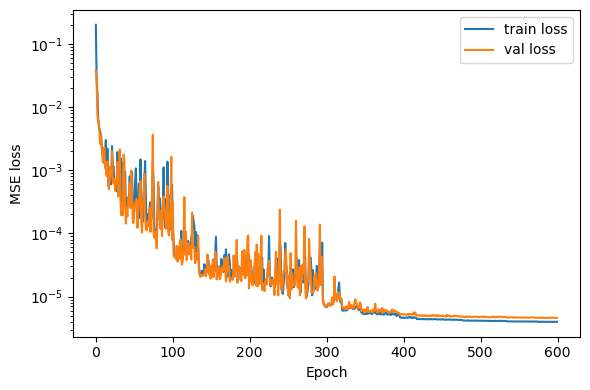

In [23]:
# Part11 Plot the training history
plt.figure(figsize=(6, 4))
plt.semilogy(train_hist, label="train loss")
plt.semilogy(val_hist, label="val loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.legend()
plt.tight_layout()
plt.show()